# 01 Initial data analysis: nursing home staffing, Q2 2024

Phase 2 of the build. This notebook profiles the source files before anything is built:
schema and keys, missing values, duplicates, outliers, relationships between files, and a reconciliation of
staffing numbers against CMS's published values. Section 9 compares every number measured here with the
figures the design doc, and section 10 holds the findings note.

**How to run.** Open it from the repo's `analysis/` folder with the "Python 3.12 (nh-staffing)" kernel and run
all cells (about a minute). It reads the files in `~/Downloads/Nursing_Homes_data`, including the monthly files
from Phase 1 step 4; set the `NH_DATA` environment variable to read them from somewhere else. DuckDB queries
the CSVs in place, so nothing is loaded into a database. Charts are saved to `analysis/figures/`.

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

DATA = Path(os.environ.get("NH_DATA", Path.home() / "Downloads" / "Nursing_Homes_data"))
MONTHLY = DATA / "monthly"
DOCS = Path("..") / "docs"
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.4f}".format)
con = duckdb.connect()


def q(sql):
    """Run SQL in DuckDB and return a pandas DataFrame."""
    return con.sql(sql).df()


def csv(name):
    """read_csv() for a supporting file, every column as text so CCNs keep their leading zeros."""
    return f"read_csv('{DATA / name}', header=true, all_varchar=true)"


found = {}  # numbers measured here; section 9 compares them with the build guide
print("Reading from", DATA)

Matplotlib is building the font cache; this may take a moment.


Reading from /Users/ryankirsch/Downloads/Nursing_Homes_data


## 1. Inventory

The Phase 1 inventory: one row per file with its size, encoding, line endings, columns, rows and check status.

In [2]:
inventory = pd.read_csv(DOCS / "source_inventory.csv")
inventory[["columns", "rows"]] = inventory[["columns", "rows"]].astype("Int64")   # the PDF has neither
inventory[["file", "bytes", "encoding", "line_endings", "columns", "rows", "status"]]

,file,bytes,encoding,line_endings,columns,rows,status
0,FY_2024_SNF_VBP_Aggregate_Performance.csv,551,utf-8,CRLF,9,1,OK
1,FY_2024_SNF_VBP_Facility_Performance.csv,1784908,utf-8,LF,20,10858,OK
2,NH_CitationDescriptions_Oct2024.csv,96299,utf-8,CRLF,5,641,OK
3,NH_CovidVaxAverages_20241027.csv,1895,utf-8,CRLF,4,54,OK
4,NH_CovidVaxProvider_20241027.csv,621424,utf-8,CRLF,5,14814,OK
5,NH_DataCollectionIntervals_Oct2024.csv,5763,utf-8,CRLF,6,45,OK
6,NH_Data_Dictionary.pdf,673079,NaN,NaN,<NA>,<NA>,OK
7,NH_FireSafetyCitations_Oct2024.csv,69213056,utf-8,CRLF,24,200003,OK
8,NH_HealthCitations_Oct2024.csv,158941610,utf-8,CRLF,23,402424,OK
9,NH_HlthInspecCutpointsState_Oct2024.csv,3653,utf-8,CRLF,6,53,OK


## 2. Schema and keys

The master file is profiled from the three UTF-8 monthly files, not the Windows-1252 original. ID columns are
forced to text (so `PROVNUM` keeps letters and leading zeros), hours to doubles and the census to an integer.
Supporting files are read with every column as text; later cells cast what they need.

In [3]:
first_month = sorted(MONTHLY.glob("PBJ_Daily_Nurse_Staffing_2024_*.csv"))[0]
with open(first_month, encoding="utf-8") as fh:
    pbj_columns = fh.readline().strip().split(",")
pbj_types = {c: "DOUBLE" if c.startswith("Hrs_") else "INTEGER" if c == "MDScensus" else "VARCHAR"
             for c in pbj_columns}

con.sql(f"""
    create or replace view pbj as
    select * from read_csv('{MONTHLY / "PBJ_Daily_Nurse_Staffing_2024_*.csv"}', header=true, types={pbj_types})
""")
supporting = {
    "provider": "NH_ProviderInfo_Oct2024.csv",
    "state_avg": "NH_StateUSAverages_Oct2024.csv",
    "claims": "NH_QualityMsr_Claims_Oct2024.csv",
    "qrp": "Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024.csv",
    "vbp": "FY_2024_SNF_VBP_Facility_Performance.csv",
}
for view, file in supporting.items():
    con.sql(f"create or replace view {view} as select * from {csv(file)}")

q("describe pbj")[["column_name", "column_type"]].T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32
column_name,PROVNUM,PROVNAME,CITY,STATE,COUNTY_NAME,COUNTY_FIPS,CY_Qtr,WorkDate,MDScensus,Hrs_RNDON,Hrs_RNDON_emp,Hrs_RNDON_ctr,Hrs_RNadmin,Hrs_RNadmin_emp,Hrs_RNadmin_ctr,Hrs_RN,Hrs_RN_emp,Hrs_RN_ctr,Hrs_LPNadmin,Hrs_LPNadmin_emp,Hrs_LPNadmin_ctr,Hrs_LPN,Hrs_LPN_emp,Hrs_LPN_ctr,Hrs_CNA,Hrs_CNA_emp,Hrs_CNA_ctr,Hrs_NAtrn,Hrs_NAtrn_emp,Hrs_NAtrn_ctr,Hrs_MedAide,Hrs_MedAide_emp,Hrs_MedAide_ctr
column_type,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,INTEGER,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE,DOUBLE


In [4]:
for view in supporting:
    cols = q(f"describe {view}")["column_name"].tolist()
    print(f"{view}: {len(cols)} columns, starting {cols[:4]}")

provider: 103 columns, starting ['CMS Certification Number (CCN)', 'Provider Name', 'Provider Address', 'City/Town']
state_avg: 48 columns, starting ['State or Nation', 'Cycle 1 Total Number of Health Deficiencies', 'Cycle 1 Total Number of Fire Safety Deficiencies', 'Cycle 2 Total Number of Health Deficiencies']
claims: 17 columns, starting ['CMS Certification Number (CCN)', 'Provider Name', 'Provider Address', 'City/Town']
qrp: 16 columns, starting ['CMS Certification Number (CCN)', 'Provider Name', 'Address Line 1', 'City/Town']
vbp: 20 columns, starting ['SNF VBP Program Ranking', 'Footnote -- SNF VBP Program Ranking', 'CMS Certification Number (CCN)', 'Provider Name']


Candidate keys: a key is good when the number of distinct key values equals the number of rows.

In [5]:
CCN = '"CMS Certification Number (CCN)"'
keys = q(f"""
    select 'master file' as dataset, 'PROVNUM + WorkDate' as candidate_key,
           count(*) as rows, count(distinct PROVNUM || '|' || WorkDate) as distinct_keys from pbj
    union all
    select 'provider info', 'CCN', count(*), count(distinct {CCN}) from provider
    union all
    select 'claims measures', 'CCN + Measure Code', count(*), count(distinct {CCN} || '|' || "Measure Code") from claims
    union all
    select 'quality program', 'CCN + Measure Code', count(*), count(distinct {CCN} || '|' || "Measure Code") from qrp
    union all
    select 'value-based purchasing', 'CCN', count(*), count(distinct {CCN}) from vbp
    union all
    select 'state averages', 'State or Nation', count(*), count(distinct "State or Nation") from state_avg
""")
keys["unique"] = keys["rows"] == keys["distinct_keys"]
found["master rows"] = int(keys.loc[0, "rows"])
keys

,dataset,candidate_key,rows,distinct_keys,unique
0,master file,PROVNUM + WorkDate,1325324,1325324,True
1,provider info,CCN,14814,14814,True
2,claims measures,CCN + Measure Code,59256,59256,True
3,quality program,CCN + Measure Code,711072,711072,True
4,value-based purchasing,CCN,10858,10858,True
5,state averages,State or Nation,54,54,True


CCNs are always six characters, and some contain a letter, so a CCN must stay text everywhere.

In [6]:
ccn_shape = q(f"""
    select 'master file' as source,
           count(distinct PROVNUM) as facilities,
           count(distinct PROVNUM) filter (where length(PROVNUM) <> 6) as not_six_characters,
           count(distinct PROVNUM) filter (where regexp_matches(PROVNUM, '[A-Za-z]')) as with_a_letter
    from pbj
    union all
    select 'provider info', count(distinct ccn), count(distinct ccn) filter (where length(ccn) <> 6),
           count(distinct ccn) filter (where regexp_matches(ccn, '[A-Za-z]'))
    from (select {CCN} as ccn from provider)
""")
found["master facilities"] = int(ccn_shape.loc[0, "facilities"])
found["master CCNs with a letter"] = int(ccn_shape.loc[0, "with_a_letter"])
found["provider CCNs with a letter"] = int(ccn_shape.loc[1, "with_a_letter"])
ccn_shape

,source,facilities,not_six_characters,with_a_letter
0,master file,14564,0,235
1,provider info,14814,0,261


## 3. Missing values

Percent missing per column. DuckDB reads an empty field as NULL, so `null_percentage` counts blanks. The chart is
the brief's "histogram for missing values".

In [7]:
def missing(view):
    s = q(f"summarize {view}")[["column_name", "null_percentage"]]
    s["null_percentage"] = s["null_percentage"].astype(float)
    return s.sort_values("null_percentage", ascending=False).reset_index(drop=True)


pbj_missing = missing("pbj")
provider_missing = missing("provider")
found["master columns with missing values"] = int((pbj_missing.null_percentage > 0).sum())
print("Master file columns with any missing value:", found["master columns with missing values"])
print("Provider info columns with any missing value:", int((provider_missing.null_percentage > 0).sum()), "of", len(provider_missing))

Master file columns with any missing value: 0
Provider info columns with any missing value: 71 of 103


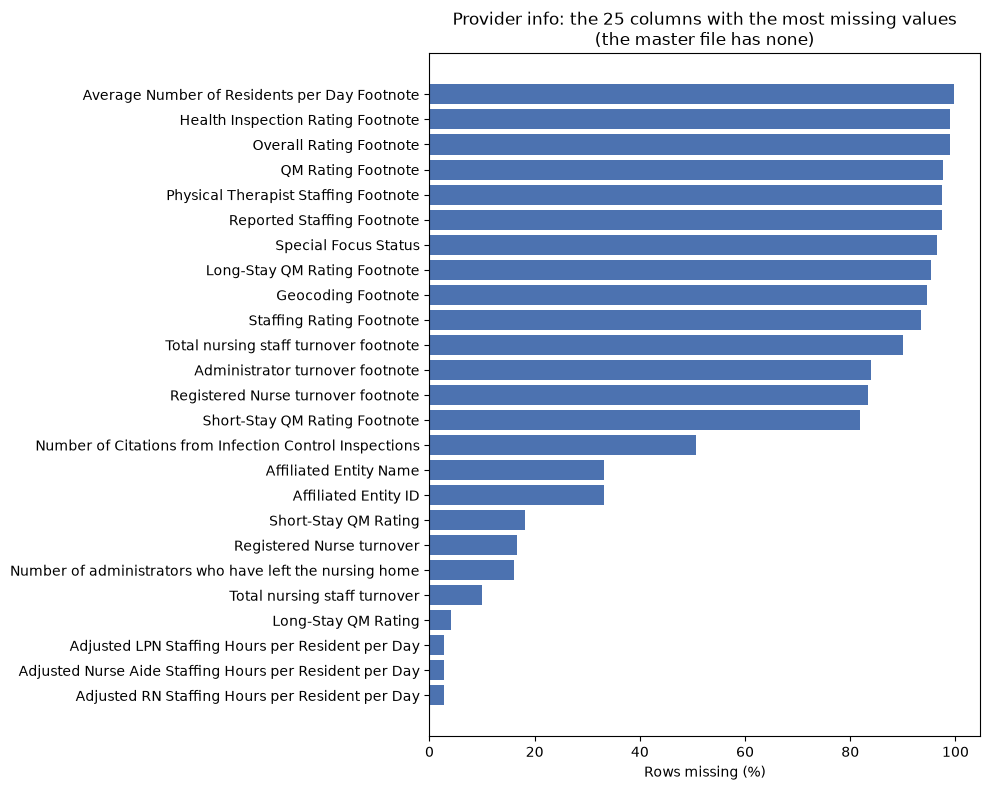

In [8]:
top = provider_missing[provider_missing.null_percentage > 0].head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top.column_name, top.null_percentage, color="#4C72B0")
ax.set_xlabel("Rows missing (%)")
ax.set_title("Provider info: the 25 columns with the most missing values\n(the master file has none)")
fig.tight_layout()
fig.savefig(FIGS / "missing_values_provider_info.png", dpi=150)
plt.show()

The provider-info blanks that matter for this project, and the claims measure scores:

In [9]:
blanks = q("""
    select count(*) filter (where "Reported Total Nurse Staffing Hours per Resident per Day" is null) as reported_total_hprd,
           count(*) filter (where "Total nursing staff turnover" is null) as nursing_turnover,
           count(*) filter (where "Staffing Rating" is null) as staffing_rating,
           count(*) filter (where "Average Number of Residents per Day" is null) as residents_per_day,
           count(*) filter (where "Number of Certified Beds" is null) as certified_beds
    from provider
""")
claims_blank = q('select count(*) filter (where "Adjusted Score" is null) as blank, count(*) as rows from claims')
for col in blanks.columns:
    found[f"provider blank: {col}"] = int(blanks.loc[0, col])
found["claims adjusted score blank"] = int(claims_blank.loc[0, "blank"])
display(blanks)
claims_blank

,reported_total_hprd,nursing_turnover,staffing_rating,residents_per_day,certified_beds
0,386,1473,201,48,0


,blank,rows
0,12124,59256


Quality-program scores mix numbers with text labels, so silver must cast them safely and keep the label.

In [10]:
labels = q("""
    select "Score" as label, count(*) as rows from qrp
    where try_cast("Score" as double) is null and "Score" is not null
    group by 1 order by 2 desc
""")
found["quality program 'Not Available' rows"] = int(labels.loc[labels.label == "Not Available", "rows"].sum())
labels

,label,rows
0,Not Available,95258
1,No Different than the National Rate,31182
2,Better than the National Rate,3043
3,Worse than the National Rate,2008


## 4. Duplicates and internal consistency

No key should repeat. In the master file, employed plus contract hours should equal the total for every role,
and no value should be blank or negative.

In [11]:
dups = q(f"""
    select (select count(*) from (select PROVNUM, WorkDate from pbj group by all having count(*) > 1)) as facility_days,
           (select count(*) from (select {CCN} from provider group by all having count(*) > 1)) as provider_ccns,
           (select count(*) from (select {CCN}, "Measure Code" from claims group by all having count(*) > 1)) as claims_pairs,
           (select count(*) from (select {CCN}, "Measure Code" from qrp group by all having count(*) > 1)) as qrp_pairs
""")
found["duplicate facility-days"] = int(dups.loc[0, "facility_days"])
dups

,facility_days,provider_ccns,claims_pairs,qrp_pairs
0,0,0,0,0


In [12]:
roles = ["RNDON", "RNadmin", "RN", "LPNadmin", "LPN", "CNA", "NAtrn", "MedAide"]
numeric = [c for c in pbj_columns if c.startswith("Hrs_") or c == "MDScensus"]
not_total = " + ".join(f"count(*) filter (where abs(Hrs_{r} - Hrs_{r}_emp - Hrs_{r}_ctr) > 0.005)" for r in roles)
negative = " + ".join(f"count(*) filter (where {c} < 0)" for c in numeric)
blank = " + ".join(f"count(*) filter (where {c} is null)" for c in pbj_columns)
consistency = q(f"""
    select {not_total} as employed_plus_contract_not_total,
           {negative} as negative_values,
           {blank} as blank_values
    from pbj
""")
found["employed + contract not equal to total"] = int(consistency.loc[0, "employed_plus_contract_not_total"])
consistency

,employed_plus_contract_not_total,negative_values,blank_values
0,0,0,0


## 5. Outliers

A daily view with CMS's role definitions: RN = RN director of nursing + RN admin + RN; LPN = LPN admin + LPN;
aide = certified nurse aide + aide in training + medication aide. Contract hours are summed the same way.

In [13]:
ctr = " + ".join(f"Hrs_{r}_ctr" for r in roles)
con.sql(f"""
    create or replace view pbj_daily as
    select PROVNUM                                   as ccn,
           STATE                                     as state,
           strptime(WorkDate, '%Y%m%d')::date        as work_date,
           MDScensus                                 as census,
           Hrs_RNDON + Hrs_RNadmin + Hrs_RN          as rn_hours,
           Hrs_LPNadmin + Hrs_LPN                    as lpn_hours,
           Hrs_CNA + Hrs_NAtrn + Hrs_MedAide         as aide_hours,
           rn_hours + lpn_hours + aide_hours         as nurse_hours,
           {ctr}                                     as contract_hours
    from pbj
""")

day_types = q("""
    select count(*) filter (where census = 0)                                     as zero_census_days,
           count(distinct ccn) filter (where census = 0)                          as zero_census_facilities,
           count(*) filter (where census = 0 and nurse_hours > 0)                 as zero_census_days_with_hours,
           count(*) filter (where census > 0 and nurse_hours = 0)                 as residents_no_hours_days,
           count(distinct ccn) filter (where census > 0 and nurse_hours = 0)      as residents_no_hours_facilities,
           count(*) filter (where census > 0 and nurse_hours / census > 24)       as above_24_hprd_days,
           count(distinct ccn) filter (where census > 0 and nurse_hours / census > 24) as above_24_hprd_facilities,
           count(*) filter (where census > 0 and rn_hours = 0)                    as residents_no_rn_days,
           count(distinct ccn) filter (where census > 0 and rn_hours = 0)         as residents_no_rn_facilities
    from pbj_daily
""")
for col in day_types.columns:
    found[col.replace("_", " ")] = int(day_types.loc[0, col])
day_types.T.rename(columns={0: "count"})

,count
zero_census_days,320
zero_census_facilities,12
zero_census_days_with_hours,165
residents_no_hours_days,2522
residents_no_hours_facilities,95
above_24_hprd_days,75
above_24_hprd_facilities,17
residents_no_rn_days,10817
residents_no_rn_facilities,1670


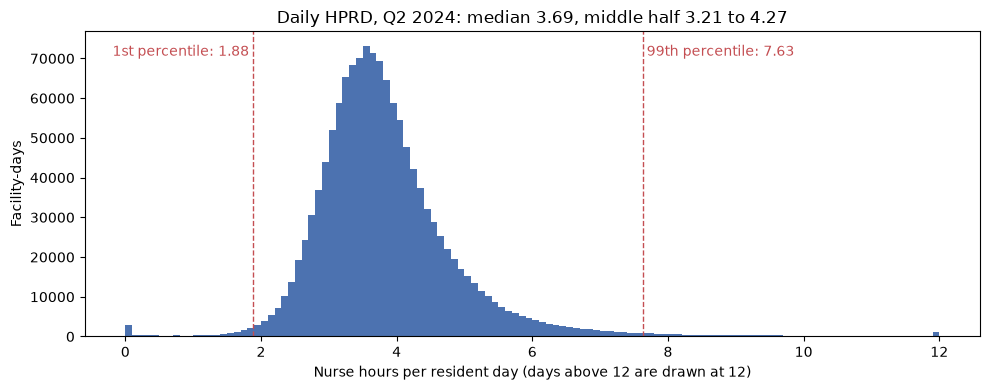

In [14]:
pct = q("""
    select quantile_cont(nurse_hours / census, [0.01, 0.25, 0.5, 0.75, 0.99]) as p
    from pbj_daily where census > 0
""").loc[0, "p"]
found["median daily HPRD"] = round(float(pct[2]), 2)
hprd = q("select nurse_hours / census as hprd from pbj_daily where census > 0")["hprd"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(hprd.clip(upper=12), bins=120, color="#4C72B0")
top_y = ax.get_ylim()[1]
for value, label, side in [(pct[0], "1st percentile", "right"), (pct[4], "99th percentile", "left")]:
    ax.axvline(value, color="#C44E52", linestyle="--", linewidth=1)
    ax.text(value, top_y * 0.92, f" {label}: {value:.2f} ", color="#C44E52", ha=side)
ax.set_xlabel("Nurse hours per resident day (days above 12 are drawn at 12)")
ax.set_ylabel("Facility-days")
ax.set_title(f"Daily HPRD, Q2 2024: median {pct[2]:.2f}, middle half {pct[1]:.2f} to {pct[3]:.2f}")
fig.tight_layout()
fig.savefig(FIGS / "daily_hprd_histogram.png", dpi=150)
plt.show()

The ten most extreme facility-days. Days above 24 hours per resident are physically implausible.

In [15]:
q("""
    select ccn, work_date, census, round(lpn_hours, 2) as lpn_hours, round(nurse_hours, 2) as nurse_hours,
           round(nurse_hours / census, 1) as hprd
    from pbj_daily where census > 0
    order by nurse_hours / census desc limit 10
""")

,ccn,work_date,census,lpn_hours,nurse_hours,hprd
0,045477,2024-05-05,1,31.3300,193.0800,193.1000
1,045477,2024-05-03,1,37.7800,182.5700,182.6000
2,145446,2024-05-25,83,"13,946.2500","14,079.0000",169.6000
3,395068,2024-06-28,1,12.7000,160.4000,160.4000
4,045477,2024-05-04,1,37.4000,154.0400,154.0000
5,325214,2024-06-22,1,11.5000,150.9500,151.0000
6,325214,2024-06-25,1,3.0000,129.4000,129.4000
7,185293,2024-05-23,3,81.0000,379.7500,126.6000
8,366134,2024-06-27,1,12.2500,100.0000,100.0000
9,325214,2024-06-24,1,0.0000,95.7100,95.7000


## 6. Relationships between files

How the master file and provider info overlap, and whether every facility-level file's CCNs exist in
provider info.

In [16]:
overlap = q(f"""
    with m as (select distinct PROVNUM as ccn from pbj),
         p as (select {CCN} as ccn, "Reported Staffing Footnote" as staffing_footnote from provider)
    select (select count(*) from m)                                             as master_facilities,
           (select count(*) from m where ccn in (select ccn from p))            as in_provider_info,
           (select count(*) from m where ccn not in (select ccn from p))        as missing_from_provider_info,
           (select count(*) from p where ccn not in (select ccn from m))        as provider_without_staffing,
           (select count(*) from p where ccn not in (select ccn from m)
                                     and staffing_footnote = '6')              as of_which_footnote_6,
           (select count(distinct STATE) from pbj)                              as master_states,
           (select count(distinct "State") from provider)                       as provider_states
""")
for col in ["missing_from_provider_info", "provider_without_staffing", "of_which_footnote_6", "master_states"]:
    found[col.replace("_", " ")] = int(overlap.loc[0, col])
display(overlap.T.rename(columns={0: "count"}))
print("States only in provider info:",
      q('select distinct "State" as s from provider except select distinct STATE from pbj')["s"].tolist())

,count
master_facilities,14564
in_provider_info,14547
missing_from_provider_info,17
provider_without_staffing,267
of_which_footnote_6,254
master_states,52
provider_states,53


States only in provider info: ['GU']


In [17]:
q(f"""
    select PROVNUM as ccn, any_value(PROVNAME) as name, any_value(STATE) as state
    from pbj where PROVNUM not in (select {CCN} from provider)
    group by 1 order by 1
""")

,ccn,name,state
0,146038,PRAIRIE CITY REHAB & H C,IL
1,155305,SKILLED CARING CENTER OF MEMORIAL HOSPITAL,IN
2,155853,PARK PLACE HEALTH AND WELLNESS CENTER,IN
3,165331,MORNING SUN CARE CENTER,IA
4,175077,LIFE CARE CENTER OF OSAWATOMIE,KS
5,205118,NARRAGUAGUS BAY HEALTH CARE FACILITY,ME
6,235301,MCAULEY REHABILITATION AND WELLNESS,MI
7,245395,CROSSROADS CARE CENTER,MN
8,265384,RIDGEVIEW LIVING COMMUNITY,MO
9,265847,SONSHINE MANOR,MO


In [18]:
facility_files = [
    "NH_QualityMsr_Claims_Oct2024.csv", "NH_QualityMsr_MDS_Oct2024.csv",
    "Skilled_Nursing_Facility_Quality_Reporting_Program_Provider_Data_Oct2024.csv",
    "NH_Ownership_Oct2024.csv", "NH_Penalties_Oct2024.csv", "NH_HealthCitations_Oct2024.csv",
    "NH_FireSafetyCitations_Oct2024.csv", "NH_SurveyDates_Oct2024.csv", "NH_SurveySummary_Oct2024.csv",
    "NH_CovidVaxProvider_20241027.csv", "FY_2024_SNF_VBP_Facility_Performance.csv",
    "Swing_Bed_SNF_data_Oct2024.csv",
]
coverage = pd.concat([q(f"""
    select '{f}' as file, count(distinct c) as ccns,
           count(distinct c) filter (where c in (select {CCN} from provider)) as in_provider_info
    from (select {CCN} as c from {csv(f)})
""") for f in facility_files], ignore_index=True)
coverage["not_in_provider_info"] = coverage.ccns - coverage.in_provider_info
found["VBP CCNs in provider info"] = int(coverage.loc[coverage.file.str.startswith("FY_2024"), "in_provider_info"].iloc[0])
found["other facility files fully matched"] = int((coverage.not_in_provider_info == 0).sum())
coverage

,file,ccns,in_provider_info,not_in_provider_info
0,NH_QualityMsr_Claims_Oct2024.csv,14814,14814,0
1,NH_QualityMsr_MDS_Oct2024.csv,14814,14814,0
2,Skilled_Nursing_Facility_Quality_Reporting_Pro...,14814,14814,0
3,NH_Ownership_Oct2024.csv,14814,14814,0
4,NH_Penalties_Oct2024.csv,9255,9255,0
5,NH_HealthCitations_Oct2024.csv,14719,14719,0
6,NH_FireSafetyCitations_Oct2024.csv,14019,14019,0
7,NH_SurveyDates_Oct2024.csv,14814,14814,0
8,NH_SurveySummary_Oct2024.csv,14814,14814,0
9,NH_CovidVaxProvider_20241027.csv,14814,14814,0


## 7. Reconciliation preview

Our Q2 HPRD per facility against CMS's published value in provider info, which covers April 1 to June 30, 2024
(the `STAFFING_LEVELS` row of the data collection intervals file). CMS leaves out hours worked on days with zero
census; the second rule counts every day, to show why that matters.

In [19]:
display(q("""
    select * from read_csv('{}', header=true, all_varchar=true)
    where "Measure Code" in ('STAFFING_LEVELS', 'STAFFING_TURNOVER')
""".format(DATA / "NH_DataCollectionIntervals_Oct2024.csv")))

recon = q(f"""
    with ours as (
        select ccn,
               sum(nurse_hours) filter (where census > 0) / nullif(sum(census), 0) as hprd_cms_rule,
               sum(nurse_hours) / nullif(sum(census), 0)                         as hprd_every_day
        from pbj_daily group by ccn)
    select ours.*, try_cast(p."Reported Total Nurse Staffing Hours per Resident per Day" as double) as cms_hprd
    from ours join provider p on p.{CCN} = ours.ccn
    where try_cast(p."Reported Total Nurse Staffing Hours per Resident per Day" as double) > 0
""")
recon["gap_cms_rule"] = recon.hprd_cms_rule / recon.cms_hprd - 1
recon["gap_every_day"] = recon.hprd_every_day / recon.cms_hprd - 1
summary = pd.DataFrame({
    "rule": ["zero-census days dropped (CMS)", "every day counted"],
    "facilities_compared": [len(recon), len(recon)],
    "within_0.1%": [(recon.gap_cms_rule.abs() <= 0.001).sum(), (recon.gap_every_day.abs() <= 0.001).sum()],
    "more_than_1%_off": [(recon.gap_cms_rule.abs() > 0.01).sum(), (recon.gap_every_day.abs() > 0.01).sum()],
    "largest_gap_%": [recon.gap_cms_rule.abs().max() * 100, recon.gap_every_day.abs().max() * 100],
})
found["facilities reconciled"] = len(recon)
found["within 0.1% under CMS rule"] = int(summary.loc[0, "within_0.1%"])
pushed = (recon.gap_every_day.abs() > 0.01) & (recon.gap_cms_rule.abs() <= 0.01)
found["pushed past 1% by counting every day"] = int(pushed.sum())
summary

,Measure Code,Measure Description,Data Collection Period From Date,Data Collection Period Through Date,Measure Date Range,Processing Date
0,STAFFING_LEVELS,Reporting Period for Nursing Home Staffing Lev...,04/01/2024,06/30/2024,None,20241001
1,STAFFING_TURNOVER,Reporting Period for Nursing Home Staff Turnov...,04/01/2023,03/31/2024,None,20241001


,rule,facilities_compared,within_0.1%,more_than_1%_off,largest_gap_%
0,zero-census days dropped (CMS),14415,14414,1,11.3597
1,every day counted,14415,14407,7,80.8801


The facilities that miss under either rule. The CMS-rule column is about zero for all but one; the every-day
column shows what zero-census days with hours do to a quarterly number.

In [20]:
recon[(recon.gap_cms_rule.abs() > 0.001) | (recon.gap_every_day.abs() > 0.01)].sort_values("gap_every_day", key=abs, ascending=False)

,ccn,hprd_cms_rule,hprd_every_day,cms_hprd,gap_cms_rule,gap_every_day
1321,345512,3.6643,6.6281,3.6643,0.0000,0.8088
831,045477,6.8559,10.2826,6.8559,0.0000,0.4998
5196,375310,3.5997,4.4542,3.5997,-0.0000,0.2374
12748,165383,3.9661,3.9661,3.5615,0.1136,0.1136
4042,335869,10.9457,11.4956,10.9457,-0.0000,0.0502
12975,235590,4.5456,4.7097,4.5456,0.0000,0.0361
3557,045212,3.2650,3.3393,3.2650,-0.0000,0.0227


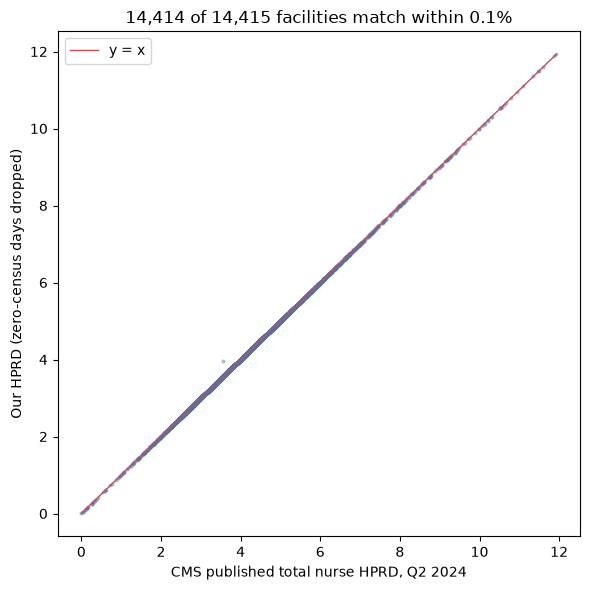

In [21]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(recon.cms_hprd, recon.hprd_cms_rule, s=4, alpha=0.35, color="#4C72B0")
upper = max(recon.cms_hprd.max(), recon.hprd_cms_rule.max())
ax.plot([0, upper], [0, upper], color="#C44E52", linewidth=1, label="y = x")
ax.set_xlabel("CMS published total nurse HPRD, Q2 2024")
ax.set_ylabel("Our HPRD (zero-census days dropped)")
ax.set_title(f"{found['within 0.1% under CMS rule']:,} of {len(recon):,} facilities match within 0.1%")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "reconciliation_scatter.png", dpi=150)
plt.show()

CMS keeps implausible days. The biggest one (the most nurse hours on any day above 24 HPRD) shows how much one
day moves a quarterly number.

In [22]:
worst = q("""
    select ccn, work_date from pbj_daily
    where census > 0 and nurse_hours / census > 24
    order by nurse_hours desc limit 1
""")
ccn, day = worst.loc[0, "ccn"], worst.loc[0, "work_date"]
one = q(f"""
    select sum(nurse_hours) filter (where census > 0) / sum(census)                              as with_that_day,
           sum(nurse_hours) filter (where census > 0 and work_date <> DATE '{day:%Y-%m-%d}')
             / sum(census) filter (where work_date <> DATE '{day:%Y-%m-%d}')                     as without_that_day,
           (select try_cast("Reported Total Nurse Staffing Hours per Resident per Day" as double)
            from provider where {CCN} = '{ccn}')                                                  as cms_published
    from pbj_daily where ccn = '{ccn}'
""")
found["extreme day: CMS HPRD with it"] = round(float(one.loc[0, "cms_published"]), 2)
found["extreme day: our HPRD without it"] = round(float(one.loc[0, "without_that_day"]), 2)
print(f"Facility {ccn}, day {day:%Y-%m-%d}")
one

Facility 145446, day 2024-05-25


,with_that_day,without_that_day,cms_published
0,4.5663,2.7340,4.5663


## 8. Occupancy, weighting and early signals

Occupancy is average daily census over certified beds. CMS's state and national averages are simple means of
facility values; weighting by resident days gives a different (lower) national figure. The last cell has early
signals for Phase 5, not conclusions.

In [23]:
fac = q(f"""
    select d.ccn,
           avg(d.census)                                                   as avg_daily_census,
           any_value(try_cast(p."Average Number of Residents per Day" as double)) as cms_residents_per_day,
           any_value(try_cast(p."Number of Certified Beds" as double))   as certified_beds,
           sum(d.nurse_hours) filter (where d.census > 0) / nullif(sum(d.census), 0) as hprd
    from pbj_daily d join provider p on p.{CCN} = d.ccn
    group by d.ccn
""")
fac["occupancy"] = fac.avg_daily_census / fac.certified_beds
found["mean absolute census difference vs provider info"] = round(float((fac.avg_daily_census - fac.cms_residents_per_day).abs().mean()), 2)
found["facilities above 100% occupancy"] = int((fac.occupancy > 1).sum())
found["facilities above 110% occupancy"] = int((fac.occupancy > 1.1).sum())
found["highest occupancy %"] = round(float(fac.occupancy.max() * 100))
found["corr occupancy vs HPRD (at or under 100%)"] = round(float(fac.loc[fac.occupancy <= 1, ["occupancy", "hprd"]].corr().iloc[0, 1]), 2)
fac.describe()[["avg_daily_census", "certified_beds", "occupancy", "hprd"]]

,avg_daily_census,certified_beds,occupancy,hprd
count,"14,547.0000","14,547.0000","14,547.0000","14,547.0000"
mean,83.4773,107.3362,0.7851,3.8330
std,48.9298,58.9127,0.1663,0.9341
min,1.4176,4.0000,0.0650,0.0035
25%,50.6868,66.0000,0.6851,3.2912
50%,76.0549,100.0000,0.8268,3.6639
75%,104.3736,128.0000,0.9109,4.1568
max,732.2637,843.0000,3.3176,11.9276


In [24]:
weights = q("""
    select sum(nurse_hours) filter (where census > 0) / sum(census)                                   as national_weighted,
           sum(nurse_hours) filter (where census > 0 and dayofweek(work_date) in (0, 6))
             / sum(census) filter (where dayofweek(work_date) in (0, 6))                              as weekend,
           sum(nurse_hours) filter (where census > 0 and dayofweek(work_date) not in (0, 6))
             / sum(census) filter (where dayofweek(work_date) not in (0, 6))                          as weekday,
           sum(contract_hours) / sum(nurse_hours)                                                     as contract_share
    from pbj_daily
""")
no_contract = q("select count(*) as n from (select ccn from pbj_daily group by ccn having sum(contract_hours) = 0)")
cms_national = q("""
    select try_cast("Reported Total Nurse Staffing Hours per Resident per Day" as double) as v
    from state_avg where "State or Nation" = 'NATION'
""")
found["national HPRD weighted by resident days"] = round(float(weights.loc[0, "national_weighted"]), 2)
found["facility mean HPRD"] = round(float(fac.hprd.mean()), 2)
found["CMS national average HPRD"] = round(float(cms_national.loc[0, "v"]), 2)
found["weekend HPRD"] = round(float(weights.loc[0, "weekend"]), 2)
found["weekday HPRD"] = round(float(weights.loc[0, "weekday"]), 2)
found["contract share of nurse hours %"] = round(float(weights.loc[0, "contract_share"]) * 100, 1)
found["facilities with no contract hours"] = int(no_contract.loc[0, "n"])
weights

,national_weighted,weekend,weekday,contract_share
0,3.7141,3.2500,3.8995,0.0704


## 9. Checks against the build guide

Every number the design doc and build guide quote, next to what this notebook measured. All rows should say
`True`; a `False` means the source files differ from the profiled copies or a cell needs a look.

In [25]:
expected = {
    "master rows": 1_325_324,
    "master facilities": 14_564,
    "duplicate facility-days": 0,
    "employed + contract not equal to total": 0,
    "master columns with missing values": 0,
    "master CCNs with a letter": 235,
    "provider CCNs with a letter": 261,
    "zero census days": 320,
    "zero census facilities": 12,
    "zero census days with hours": 165,
    "residents no hours days": 2_522,
    "residents no hours facilities": 95,
    "above 24 hprd days": 75,
    "above 24 hprd facilities": 17,
    "residents no rn days": 10_817,
    "residents no rn facilities": 1_670,
    "median daily HPRD": 3.69,
    "facilities reconciled": 14_415,
    "within 0.1% under CMS rule": 14_414,
    "pushed past 1% by counting every day": 6,
    "missing from provider info": 17,
    "provider without staffing": 267,
    "of which footnote 6": 254,
    "master states": 52,
    "VBP CCNs in provider info": 10_688,
    "other facility files fully matched": 10,
    "provider blank: reported_total_hprd": 386,
    "provider blank: nursing_turnover": 1_473,
    "provider blank: staffing_rating": 201,
    "provider blank: residents_per_day": 48,
    "provider blank: certified_beds": 0,
    "claims adjusted score blank": 12_124,
    "quality program 'Not Available' rows": 95_258,
    "mean absolute census difference vs provider info": 0.03,
    "facilities above 100% occupancy": 161,
    "facilities above 110% occupancy": 54,
    "highest occupancy %": 332,
    "national HPRD weighted by resident days": 3.71,
    "facility mean HPRD": 3.83,
    "CMS national average HPRD": 3.84,
    "weekend HPRD": 3.25,
    "weekday HPRD": 3.90,
    "contract share of nurse hours %": 7.0,
    "facilities with no contract hours": 5_750,
    "corr occupancy vs HPRD (at or under 100%)": -0.06,
    "extreme day: CMS HPRD with it": 4.57,
    "extreme day: our HPRD without it": 2.73,
}
def same(e, m):
    """Counts must be equal; rounded figures may differ by one in the last place."""
    if m is None:
        return False
    return abs(m - e) <= 0.011 if isinstance(e, float) else m == e


def show(v):
    return "missing" if v is None else f"{v:,}" if isinstance(v, int) else f"{v:,.2f}"


checks = pd.DataFrame(
    [(name, show(e), show(found.get(name)), same(e, found.get(name))) for name, e in expected.items()],
    columns=["check", "build guide", "measured", "match"],
)
print(f"{checks.match.sum()} of {len(checks)} checks match")
checks

47 of 47 checks match


,check,build guide,measured,match
0,master rows,"1,325,324","1,325,324",True
1,master facilities,"14,564","14,564",True
2,duplicate facility-days,0,0,True
3,employed + contract not equal to total,0,0,True
4,master columns with missing values,0,0,True
5,master CCNs with a letter,235,235,True
6,provider CCNs with a letter,261,261,True
7,zero census days,320,320,True
8,zero census facilities,12,12,True
9,zero census days with hours,165,165,True
